# Data loading and neural network classification

In this notebook, you will learn to use Heat's `DistributedDataLoader` to train a small
PyTorch neural network on the Iris dataset. We will first inspect the flowers, split
and scale their measurements, and look at a batch of training examples. We will then
train the network and check how well it predicts the species of flowers it has not seen.

We use IPyParallel to run the training cells on MPI engines. Choose one engine
for a single-process run or several engines to distribute the data and training.
Iris is small enough to fit on one process; we use it to understand the steps, rather
than to measure a speedup.

## Setup

We use IPyParallel to run the tutorial on MPI processes, also called `ranks`.
Choose how to connect with `use_external_engines`:

- `False` (default): Start a local MPI cluster inside the notebook. `n_engines`
  controls the number of processes. Use a single engine to run on one process,
  or several engines to distribute the training.
- `True`: Connect to engines you have already started using the
  [local setup notebook](setup/setup_local.ipynb).

  On Jupyter-JSC, start the engines in a terminal using:

  ```bash
  source ./setup/setup_jupiter_jsc.sh
  ```

  This script assumes the JSC training environment is available. See the
  [JSC setup notebook](setup/setup_jsc.ipynb) for the environment setup.

The external connection uses `Client(profile="default")`, as in the setup notebook.
`n_engines` only controls clusters started by this notebook. When connecting to external
engines, we use all engines in the default profile; these should be the complete MPI
engine group.

Run the setup and cleanup cells in the notebook kernel, without `%%px`. Every tutorial
code cell in between already starts with `%%px` to run on all engines. Only rank zero
displays the tables, plots, and training summaries. To change the connection settings,
run cleanup and start again from the setup cell, then rerun the tutorial cells.

In [ ]:
import ipyparallel as ipp
from ipyparallel import Client

use_external_engines = False
n_engines = 4
cluster = None
rc = None

try:
    if use_external_engines:
        rc = Client(profile="default")
        rc.activate()
    else:
        cluster = ipp.Cluster(engines="mpi", n=n_engines)
        rc = cluster.start_and_connect_sync(activate=True)

    rc[:].execute("%matplotlib inline", block=True)
    print(f"Connected to {len(rc.ids)} MPI engines.")
except BaseException:
    try:
        if rc is not None:
            rc.close()
    finally:
        if cluster is not None:
            cluster.stop_cluster_sync()
    raise

Starting 4 engines with <class 'ipyparallel.cluster.launcher.MPIEngineSetLauncher'>
100%|██████████| 4/4 [00:06<00:00,  1.60s/engine]
Connected to 4 MPI engines.


### Imports

`%%px` runs this cell and the following tutorial cells on every engine. Only rank zero
will display tables, plots, and training summaries. Imports and all Heat operations
still run on every rank, including when there is just one engine.

In [ ]:
%%px
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.datasets import load_iris
from IPython.display import display

import heat as ht
from heat.preprocessing import StandardScaler
from heat.utils.data import DistributedDataLoader, create_train_val_split

comm = ht.MPI_WORLD

if comm.rank == 0:
    print(f"Training on {comm.size} MPI process(es).")

%px:  50%|█████     | 2/4 [00:05<00:00, 19.71tasks/s]

[stdout:0] Training on 4 MPI process(es).


%px: 100%|██████████| 4/4 [00:05<00:00,  1.44s/tasks]


### Choosing a device

We use `device` to choose where the data and network will live. Set it to `"cpu"`
or `"gpu"`. Heat resolves this choice for each rank, and `torch_device` gives us the
corresponding PyTorch device. This keeps the arrays, batches, and model together
without moving each batch separately.

Choose `"gpu"` when a supported GPU is available to every engine. If you change
`device`, rerun this cell and all following tutorial cells to recreate the data,
model, and optimizer on that device.

In [ ]:
%%px
device = "cpu"  # Change to "gpu" to use the available GPU on each engine.
heat_device = ht.sanitize_device(device)
torch_device = torch.device(heat_device.torch_device)

if comm.rank == 0:
    print(f"Rank-zero device: {heat_device} | PyTorch device: {torch_device}")

[stdout:0] Rank-zero device: cpu:0 | PyTorch device: cpu


## Flowers

Each flower is described by measurements of its sepals and petals:

- Sepal length and width
- Petal length and width

They belong to the species `setosa`, `versicolor`, or `virginica`, and our goal is to
correctly classify them.

The measurements are our `features` (inputs, `X`); the species is our `label` (what we
want to predict, `y`). We represent the labels as integer class indices. After loading
the data, we can check how many samples, features, and species it contains.

In [ ]:
%%px
iris = load_iris(as_frame=True)
features = iris.data
labels = iris.target
names = iris.target_names
n_samples, n_features = features.shape
n_classes = len(names)

if comm.rank == 0:
    print(f"{n_samples} flowers | {n_features} features | {n_classes} species")
    display(features.head())

[stdout:0] 150 flowers | 4 features | 3 species


[output:0]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### Plotting the data

We can plot two measurements against one another and colour each flower by its species.
Try changing the selected measurements to see which pairs help separate the species.
The network will use all four measurements, even though this plot only shows two.

[output:0]

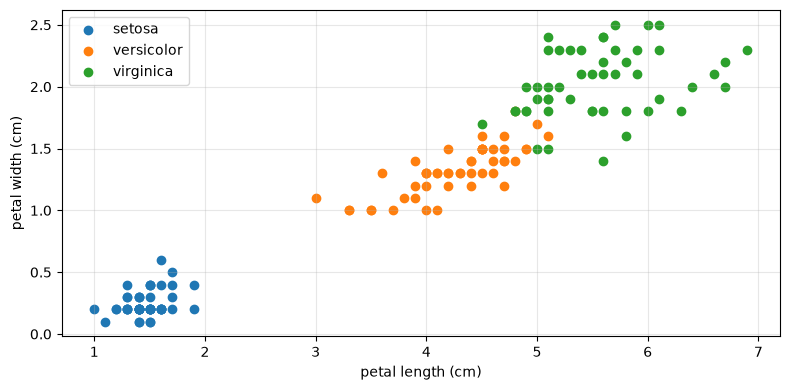

In [ ]:
%%px
feature1 = "petal length (cm)"
feature2 = "petal width (cm)"

if comm.rank == 0:
    fig, ax = plt.subplots(figsize=(8, 4))
    for i, species in enumerate(names):
        mask = labels == i
        ax.scatter(features.loc[mask, feature1], features.loc[mask, feature2], label=species)
    ax.set(xlabel=feature1, ylabel=feature2)
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

## Preparing the training data

We want to train a model that can classify a flower using these measurements.
Before we train it, we first split the dataset into two parts:

1. Training
2. Testing

The training data will be used to train the model. Once it is trained, we can use the
testing data to estimate how well it predicts the species of flowers it has not seen
during training. `train_fraction` controls how much of the data we use for training;
the rest is kept for testing.

We convert the measurements and labels to Heat arrays with `split=0`: samples are
distributed along the first axis. With one process, that process holds all samples.
With multiple processes, each process holds a portion of the rows. We then use
`create_train_val_split` to split features and labels together, keeping each flower
paired with the correct species.

The `seed` makes the shuffled split reproducible. This split does not enforce equal
species proportions in the training and test sets.

The features use `float32`, matching the network's weights. The labels use `int64`,
which PyTorch's cross-entropy loss expects for class indices.

In [ ]:
%%px
train_fraction = 0.70
seed = 42

X = ht.array(features.to_numpy(copy=True), dtype=ht.float32, split=0, device=heat_device)
y = ht.array(labels.to_numpy(copy=True), dtype=ht.int64, split=0, device=heat_device)

X_train, X_test, y_train, y_test = create_train_val_split(X, y, p=train_fraction, seed=seed)

if comm.rank == 0:
    print(f"Training: {X_train.shape[0]} flowers | Testing: {X_test.shape[0]} flowers")
    print(f"Global feature shape: {X_train.shape} | Rank-zero local shape: {X_train.lshape}")

[stdout:0] Training: 105 flowers | Testing: 45 flowers
Global feature shape: (105, 4) | Rank-zero local shape: (27, 4)


### Scaling the measurements

Before we train our model, we also scale the features. We use Heat's `StandardScaler`,
which implements `z-scoring`: it subtracts each feature's training mean and divides by
its training standard deviation. This puts the measurements on comparable scales and
can help the optimizer train the network.

We fit the scaler on the training flowers only. We then apply that same fitted
transformation to the test flowers. With multiple engines, Heat computes the training
statistics across all ranks, so these calls must run on every rank.

In [ ]:
%%px
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Loading batches

Instead of updating the network with all training flowers at once, we use small groups
called `mini-batches`. `DistributedDataLoader` accepts our Heat feature and label
arrays together and returns pairs of PyTorch tensors. Each pair contains complete
feature rows and their matching labels, ready for the network and loss.

`batch_size` sets the maximum number of flowers per process in each step. A full step
processes `batch_size * comm.size` flowers across all ranks. `shuffle=True` changes the
shared global sample order at the start of each epoch. The loader uses `seed + epoch`
to make this order reproducible for a given seed and epoch.

With `drop_last=False`, the loader repeats a few samples when necessary to give every
rank the same number of samples and batches. The last local batch can be smaller than
`batch_size`. With `drop_last=True`, it would discard the remainder, including an
incomplete local batch. Here, we keep the remainder so this small dataset is not
reduced further.

In [ ]:
%%px
batch_size = 4
train_loader = DistributedDataLoader(
    X_train_scaled,
    y_train,
    batch_size=batch_size,
    shuffle=True,
    drop_last=False,
    seed=seed,
)

if comm.rank == 0:
    print(f"Batches per process in each epoch: {len(train_loader)}")

[stdout:0] Batches per process in each epoch: 7


### Inspecting one batch

We can now look at one batch. A full feature batch has shape `(batch_size, n_features)`, with
one row per flower and one column per measurement. The matching label batch has shape
`(batch_size,)`. These are the samples received by this process.

We use `with iter(train_loader) as batches` because we stop after one batch. Leaving
this `with` block finishes outstanding communication requests. All ranks must retrieve
the batch and leave the block together, even though only rank zero prints it.

Creating an iterator advances the loader's epoch counter. After this preview, assigning
the seed again resets that counter, so training starts with the original shuffle order.

In [ ]:
%%px
with iter(train_loader) as batches:
    batch_features, batch_labels = next(batches)
    if comm.rank == 0:
        print(f"Features: {tuple(batch_features.shape)}, {batch_features.dtype}")
        print(f"Labels:   {tuple(batch_labels.shape)}, {batch_labels.dtype}")
        print("First three feature rows:", batch_features[:3])
        print("Their labels:", batch_labels[:3])

train_loader.seed = seed

[stdout:0] Features: (4, 4), torch.float32
Labels:   (4,), torch.int64
First three feature rows: tensor([[-1.1409, -0.1400, -1.2265, -1.0847],
        [ 0.4211, -0.6069,  0.6564,  0.1356],
        [-0.2998, -1.7740,  0.2570,  0.2712]])
Their labels: tensor([0, 1, 1])


## Building a neural network

We now need a model that can learn from these batches. Each flower provides
`n_features` inputs. A linear layer maps these to `hidden_size` hidden values, `ReLU`
replaces negative hidden values with zero, and a second linear layer produces
`n_classes` output scores, one for each species. We get the input and output sizes
from the dataset; you can change `hidden_size` to try a different hidden layer size.
We move the network to `torch_device` before creating the optimizer, so it uses the
same device as the data.

These scores are called `logits`. `CrossEntropyLoss` compares them with the correct
class indices and handles the required probability calculation internally, so we do
not add a softmax layer. A lower loss means the scores better match the labels.

Adam uses gradients of this loss to adjust the weights. The `learning_rate` controls
the size of the optimizer's updates.

In [ ]:
%%px
hidden_size = 8
learning_rate = 0.01

network = nn.Sequential(
    nn.Linear(n_features, hidden_size),
    nn.ReLU(),
    nn.Linear(hidden_size, n_classes),
).to(torch_device)
criterion = nn.CrossEntropyLoss()
torch_optimizer = torch.optim.Adam(network.parameters(), lr=learning_rate)

### Keeping the model shared across ranks

The data loader distributes **batches**, but does not synchronize the network's weights.
Without gradient synchronization, each rank would train a separate model on its batches.

We use Heat's `DataParallelOptimizer` and `ht.nn.DataParallel` around our PyTorch
optimizer and network. The model wrapper initializes matching weights on every rank.
With blocking updates, it averages gradients across ranks during `backward()` before
Adam updates the weights. Every rank must perform the same training steps.

Changing the number of ranks changes the effective batch size and
number of updates per epoch, so the final scores can differ between engine counts.

In [ ]:
%%px
optimizer = ht.optim.DataParallelOptimizer(torch_optimizer, blocking=True)
model = ht.nn.DataParallel(
    network,
    comm,
    optimizer,
    blocking_parameter_updates=True,
)

if comm.rank == 0:
    print(network)

[stdout:0] Sequential(
  (0): Linear(in_features=4, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=3, bias=True)
)


## Training the model

An **epoch** is one complete traversal of the loader's sample order. The `epochs` setting
controls how many times we repeat it. For every batch, we:

1. Clear gradients from the previous step with `zero_grad()`.
2. Calculate the network's logits and loss.
3. Call `backward()` to calculate and synchronize gradients.
4. Call `step()` to update the weights.

`model.train()` selects training mode. Each batch loss is an average, so we multiply it
by the number of samples before accumulating it. We sum the losses and sample counts
across ranks, then divide to obtain a sample-weighted epoch loss. This includes any
padding samples actually used in training. We detach the loss from its gradient graph
before recording it.

The context manager also closes the loader iterator if an exception interrupts a run.
Do not restrict the training loop or reductions to rank zero.

In [ ]:
%%px
epochs = 100
log_interval = 20
loss_history = []
samples_per_epoch = []

for epoch in range(epochs):
    model.train()
    local_loss_sum = 0.0
    local_samples = 0

    with iter(train_loader) as batches:
        for inputs, targets in batches:
            optimizer.zero_grad()
            logits = model(inputs)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()

            local_loss_sum += loss.detach().item() * targets.shape[0]
            local_samples += targets.shape[0]

    global_loss_sum = comm.allreduce(local_loss_sum)
    global_samples = comm.allreduce(local_samples)
    epoch_loss = global_loss_sum / global_samples
    loss_history.append(epoch_loss)
    samples_per_epoch.append(global_samples)

    if comm.rank == 0 and (epoch == 0 or (epoch + 1) % log_interval == 0):
        print(f"Epoch {epoch + 1:3d}/{epochs} | Loss: {epoch_loss:.4f}")

[stdout:0] Epoch   1/100 | Loss: 1.1341
Epoch  20/100 | Loss: 0.1129
Epoch  40/100 | Loss: 0.0400
Epoch  60/100 | Loss: 0.0230
Epoch  80/100 | Loss: 0.0167
Epoch 100/100 | Loss: 0.0110


%px: 100%|██████████| 4/4 [00:00<00:00, 24.06tasks/s]


### Plotting the training loss

We can use the loss curve to see whether training is making progress. The loss should
usually decrease overall, but it does not have to decrease at every epoch: batches are
reshuffled, and each weight update changes the predictions for later batches.

This is a training curve, not a measure of performance on unseen flowers. We check
the held-out test flowers next.

[output:0]

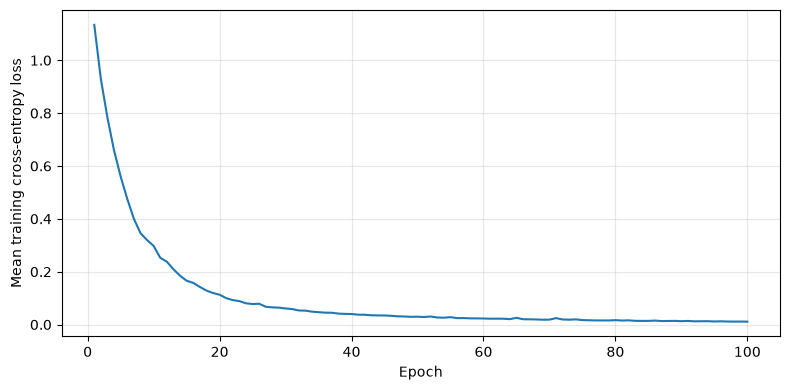

In [ ]:
%%px
if comm.rank == 0:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(1, epochs + 1), loss_history)
    ax.set(xlabel="Epoch", ylabel="Mean training cross-entropy loss")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

## Checking the scores

Accuracy is the fraction of flowers whose predicted species matches its label. We
calculate it for both the training flowers and the held-out test flowers.

`model.eval()` selects evaluation mode and `torch.no_grad()` avoids building gradient
graphs. The predicted class is the index of the largest logit; we do not update any
weights during evaluation.

For this small dataset, we evaluate each process's original local rows directly using
`.larray`, the local PyTorch tensor inside a Heat array. We sum correct predictions and
sample counts across ranks. This counts every original flower exactly once and avoids
including the loader's repeated padding samples in the final accuracy. For larger
datasets, these local rows could also be evaluated in smaller batches.

In [ ]:
%%px
def accuracy(features: ht.DNDarray, labels: ht.DNDarray) -> tuple[int, int, float]:
    """Return global correct count, sample count, and accuracy for aligned split-0 arrays."""
    with torch.no_grad():
        predictions = model(features.larray).argmax(dim=1)
        local_correct = (predictions == labels.larray).sum().item()

    correct = comm.allreduce(local_correct)
    count = comm.allreduce(labels.larray.shape[0])
    return correct, count, correct / count


model.eval()
train_correct, train_count, train_accuracy = accuracy(X_train_scaled, y_train)
test_correct, test_count, test_accuracy = accuracy(X_test_scaled, y_test)

if comm.rank == 0:
    scores = pd.DataFrame(
        {
            "Correct": [train_correct, test_correct],
            "Flowers": [train_count, test_count],
            "Accuracy": [train_accuracy, test_accuracy],
        },
        index=["Training", "Testing"],
    )
    display(scores.style.format({"Accuracy": "{:.1%}"}))

[output:0]

,Correct,Flowers,Accuracy
Training,105,105,100.0%
Testing,41,45,91.1%


### What do the scores tell us?

We now have a trained network and scores for both parts of our dataset. Training
accuracy tells us how well the network predicts the flowers used to update its
weights. Test accuracy estimates how well it predicts flowers it has not seen during
training. A much higher training score could indicate `overfitting`.

Our test set is small, so a few mistakes can noticeably change the accuracy. Small
differences should therefore be interpreted carefully. You can experiment with
`batch_size`, `hidden_size`, `learning_rate`, or `epochs` to see how these settings
affect training.

When choosing settings for a new model, we would compare them using a separate
validation set within the training data. We would then fit the chosen model on all
the training data and evaluate it on the test set. If we use the test scores to choose
settings, those scores should be treated as examples rather than a final evaluation
of a tuned model.

## Cleanup

Run this cell in the **notebook kernel without `%%px`**, after all engines have finished
the tutorial. It closes the notebook's client connection. If the notebook started the
cluster, it also stops that cluster, including for a single-engine run. Externally
started engines remain running, with their variables and model still in memory; stop
them separately when you are finished using them.

To train again after cleanup, start from the setup cell to create or reconnect to a
cluster, then rerun the tutorial cells.

In [ ]:
if rc is not None or cluster is not None:
    try:
        if rc is not None:
            rc.close()
    finally:
        rc = None
        if cluster is not None:
            cluster.stop_cluster_sync()
            cluster = None
            print("Stopped the notebook's MPI cluster.")
        else:
            print("Disconnected; externally started engines are still running.")

Stopping controller
Controller stopped: {'exit_code': 0, 'pid': 153730, 'identifier': 'ipcontroller-1793869545-2ygd-148592'}
Stopping engine(s): 1793869546
Output for ipengine-1793869545-2ygd-1793869546-148592:
2026-11-05 10:05:47.670 [KernelNanny.2] Nanny watching parent pid 153766.
2026-11-05 10:05:47.677 [KernelNanny.1] Starting kernel nanny for engine 1, pid=153765, nanny pid=153819
2026-11-05 10:05:47.678 [KernelNanny.1] Nanny watching parent pid 153765.
2026-11-05 10:05:47.714 [KernelNanny.0] Starting kernel nanny for engine 0, pid=153764, nanny pid=153821
2026-11-05 10:05:47.715 [KernelNanny.0] Nanny watching parent pid 153764.
2026-11-05 10:05:47.723 [KernelNanny.3] Starting kernel nanny for engine 3, pid=153767, nanny pid=153820
2026-11-05 10:05:47.724 [KernelNanny.3] Nanny watching parent pid 153767.
2026-11-05 10:05:47.813 [IPEngine.1.1] Loading IPython extension: storemagic
2026-11-05 10:05:47.815 [IPEngine.2.2] Loading IPython extension: storemagic
2026-11-05 10:05:47.815 

## Choosing a distributed training workflow

We have used Heat to prepare our distributed data and PyTorch to define the neural
network. We could also build a distributed training workflow entirely with PyTorch.
To choose between these approaches, we should consider what we need to do with the
data before it reaches the network.

In PyTorch’s data-parallel training, each process works on its own batch using a copy
of the same model. A `DataLoader` with a `DistributedSampler` assigns samples to the
processes, while [`DistributedDataParallel`](https://docs.pytorch.org/docs/stable/generated/torch.nn.parallel.DistributedDataParallel.html),
or `DDP`, synchronizes their gradients. This is a good starting point when samples can
be loaded and prepared independently and our main task is training a neural network.

Heat is useful when we also want to work with the distributed dataset as a whole.
For example, our scaler needs the mean and standard deviation of each measurement
across all training flowers. Heat calculates these statistics across the processes,
so every flower receives the same scaling. We can also apply other distributed array
operations and analysis methods before creating the training batches.

For larger datasets, the memory requirements also matter. In this Heat workflow,
we keep the whole dataset in distributed arrays, so it must fit in the combined
memory available to the processes. Each process holds its own part, and we also
need room for intermediate arrays and training computations.

With a PyTorch `Dataset` that reads samples from disk as needed, a
[`DataLoader`](https://docs.pytorch.org/docs/stable/data.html) can load batches without
keeping the entire dataset in memory. We then need memory for the active batches
and any prefetched batches or loading buffers, as well as the model and training
computations. This can be useful when the dataset is larger than the available
memory. The choice depends on the preprocessing and training we need; neither
approach is always faster.

In this notebook, the two libraries work together: Heat prepares the arrays and
supplies tensor batches, PyTorch provides the network, and `ht.nn.DataParallel`
synchronizes training through MPI. Iris is small enough to train on one process,
but it lets us explore this workflow.

PyTorch also offers [`DTensor`](https://docs.pytorch.org/docs/stable/distributed.tensor.html)
for distributing tensors and their operations, which is useful when building
tensor-sharding workflows within PyTorch.